# Heart Prediction
Tommy Tang <br>
Oct 11th, 2026

In [1]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers

### EDA

In [ ]:
df = pd.read_csv('../data/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
#Check overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
#Check NAs
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [5]:
#Check dtypes
features_num = df.select_dtypes(['int', 'float']).columns
features_cat = df.select_dtypes('object').columns
print(f'Df shape:{df.shape}')
print(features_num)
print(features_cat)

Df shape:(918, 12)
Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease'],
      dtype='object')
Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='object')


In [6]:
#OHE categorical features
df_ohe = pd.get_dummies(df, dtype=int)
features_ohe = df_ohe.select_dtypes(['int', 'float']).columns
print(features_ohe)
print(f'Numerical features: {len(features_ohe)}')

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_F', 'Sex_M', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_N', 'ExerciseAngina_Y', 'ST_Slope_Down',
       'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='object')
Numerical features: 21


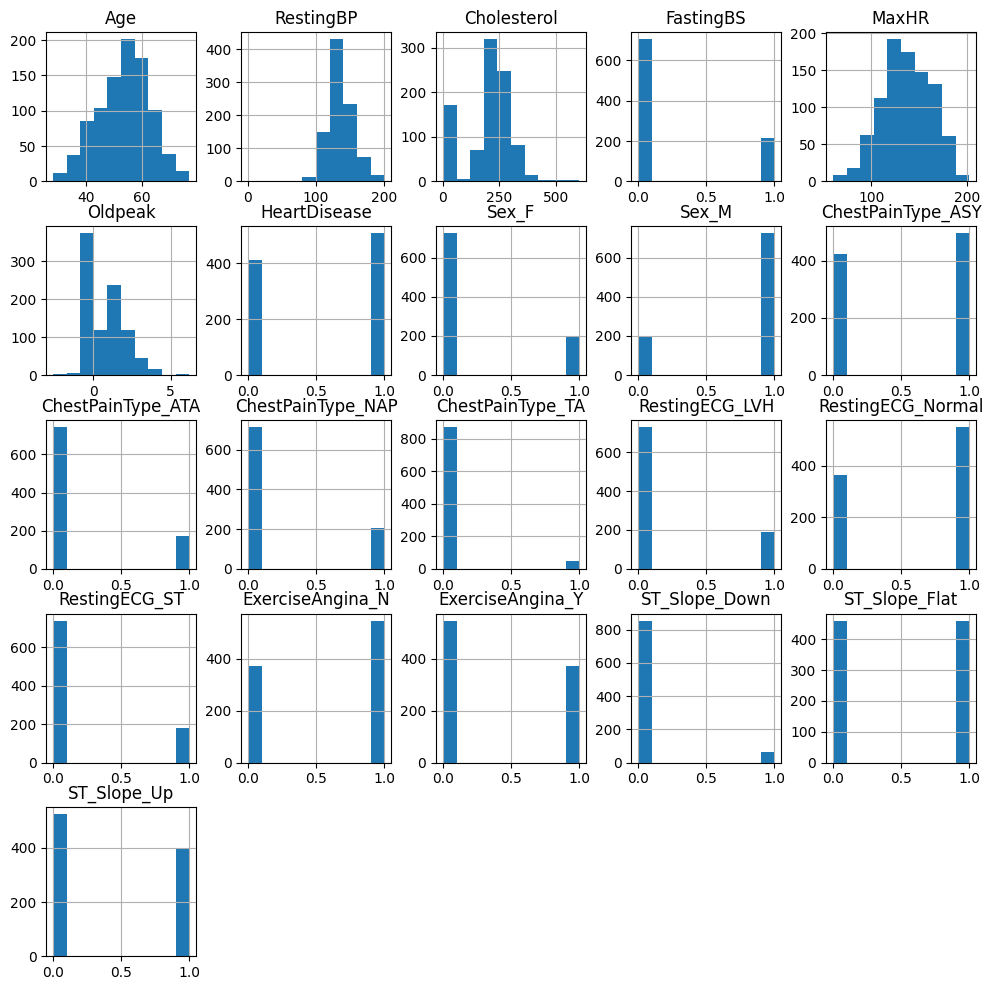

In [7]:
#Examine distributions
df_ohe.hist(figsize=(12,12));

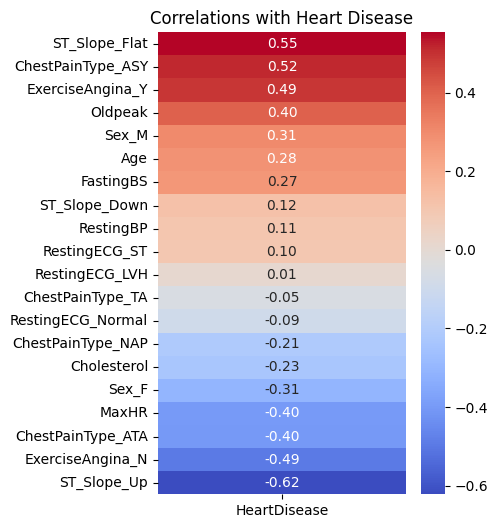

In [8]:
#Examine correlations
correlations = df_ohe.corr()[['HeartDisease']]
correlations = correlations.drop(index='HeartDisease')
plt.figure(figsize=(4,6))
plt.title('Correlations with Heart Disease')
sns.heatmap(correlations.sort_values('HeartDisease', ascending=False), cmap='coolwarm', annot=True, fmt='.2f');

### Preprocessing

In [9]:
from sklearn.model_selection import train_test_split
#No need for data cleansing, data imputation, or data balancing for this dataset.
#Separate into features and labels
X = df.copy()
y = X.pop('HeartDisease')

#Separate by feature type
features_num = X.select_dtypes(include=['int', 'float']).columns
features_cat = X.select_dtypes(include=['object', 'string']).columns

#Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
#Define preprocessing
preprocessor = ColumnTransformer([('numerical', StandardScaler(), features_num), ('categorical', OneHotEncoder(handle_unknown='ignore'), features_cat)])

#Apply preprocessing
print(f"Shape before: {X_train.shape}")
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
print(f"Shape after: {X_train.shape}")

Shape before: (734, 11)
Shape after: (734, 20)


### Training

In [35]:
#Define model
model = keras.Sequential([
    layers.Input([X_train.shape[1]]),
    layers.Dense(256, activation='relu'),
    #layers.Dropout(0.1),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    #layers.Dropout(0.1),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])

#Compile model
model.compile(
    optimizer='adam', 
    loss='binary_crossentropy', 
    metrics=[
        keras.metrics.F1Score(threshold=0.5), 
        keras.metrics.Recall(),
        keras.metrics.Precision(),
        'binary_accuracy'
    ]
)

In [36]:
callbacks = keras.callbacks.EarlyStopping(patience=10, min_delta=0.001, restore_best_weights=True)

#Train
#Keras' F1Score expects labels shaped (n, 1) like the model output
y_train_arr = y_train.to_numpy().reshape(-1, 1).astype('float32')
y_test_arr = y_test.to_numpy().reshape(-1, 1).astype('float32')
history = model.fit(X_train, y_train_arr, validation_data=(X_test, y_test_arr), batch_size=64, epochs=200, callbacks=callbacks)

Epoch 1/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - binary_accuracy: 0.7984 - f1_score: 0.8150 - loss: 0.5304 - precision_1: 0.8274 - recall_1: 0.8030 - val_binary_accuracy: 0.8750 - val_f1_score: 0.8910 - val_loss: 0.3887 - val_precision_1: 0.8624 - val_recall_1: 0.9216
Epoch 2/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - binary_accuracy: 0.8351 - f1_score: 0.8501 - loss: 0.3908 - precision_1: 0.8554 - recall_1: 0.8448 - val_binary_accuracy: 0.8859 - val_f1_score: 0.8986 - val_loss: 0.4029 - val_precision_1: 0.8857 - val_recall_1: 0.9118
Epoch 3/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - binary_accuracy: 0.8529 - f1_score: 0.8686 - loss: 0.3735 - precision_1: 0.8582 - recall_1: 0.8793 - val_binary_accuracy: 0.8696 - val_f1_score: 0.8868 - val_loss: 0.4067 - val_precision_1: 0.8545 - val_recall_1: 0.9216
Epoch 4/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - binary_accuracy: 0.8501 - f1_score: 0.8665 - loss: 0.3687 - precision_1: 0.8541 - recall_1: 0.8793 - val_binary_accuracy: 0.

<Axes: >

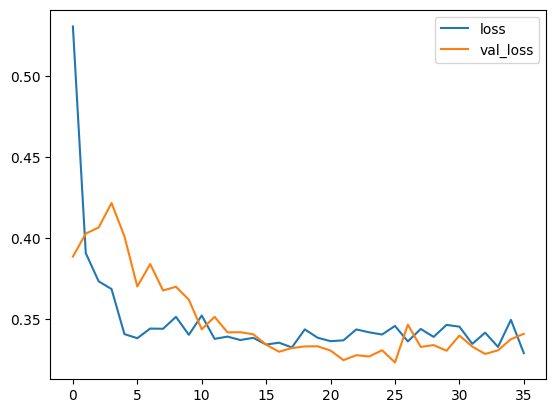

In [37]:
#Plot loss
history_df = pd.DataFrame(history.history)
history_df[['loss', 'val_loss']].plot()

<Axes: >

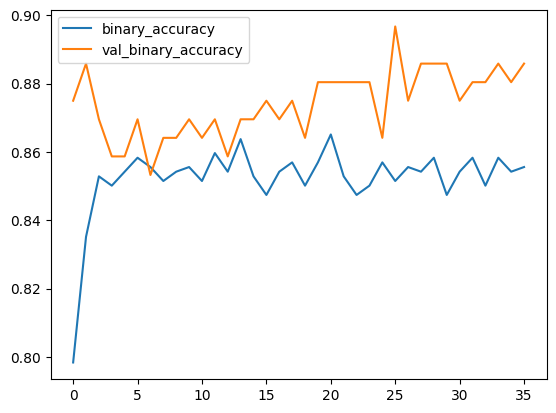

In [38]:
history_df[['binary_accuracy', 'val_binary_accuracy']].plot()

In [41]:
history_df.head()

,binary_accuracy,f1_score,loss,precision_1,recall_1,val_binary_accuracy,val_f1_score,val_loss,val_precision_1,val_recall_1
0,0.798365,0.815000,0.530435,0.827411,0.802956,0.875000,0.890995,0.388716,0.862385,0.921569
1,0.835150,0.850062,0.390847,0.855362,0.844828,0.885870,0.898551,0.402885,0.885714,0.911765
2,0.852861,0.868613,0.373472,0.858173,0.879310,0.869565,0.886792,0.406653,0.854545,0.921569
3,0.850136,0.866505,0.368716,0.854067,0.879310,0.858696,0.878505,0.421703,0.839286,0.921569
4,0.854223,0.869353,0.340978,0.861985,0.876847,0.858696,0.879629,0.401191,0.833333,0.931373


In [42]:
print(f"Best accuracy is {max(history.history['val_binary_accuracy']):.2f}")
print(f"Best F1 score is {max(history.history['val_f1_score']):.2f}")

Best accuracy is 0.90
Best F1 score is 0.91


In [43]:
#Confusion matrix
from sklearn.metrics import classification_report, confusion_matrix
y_pred = (model.predict(X_test) > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        82
           1       0.89      0.93      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.89      0.89       184
weighted avg       0.90      0.90      0.90       184

[[70 12]
 [ 7 95]]
